In [ ]:
import keras
import tensorflow as tf
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')
from sklearn.preprocessing import MinMaxScaler

In [ ]:
df1= pd.read_csv('/content/Google_Stock_Price_Train.csv')
df2= pd.read_csv('/content/Google_Stock_Price_Test.csv')

In [ ]:
df1.shape,df2.shape

((1258, 6), (20, 6))

In [ ]:
df1.head()

,Date,Open,High,Low,Close,Volume
0,1/3/2012,325.25,332.83,324.97,663.59,"7,380,500"
1,1/4/2012,331.27,333.87,329.08,666.45,"5,749,400"
2,1/5/2012,329.83,330.75,326.89,657.21,"6,590,300"
3,1/6/2012,328.34,328.77,323.68,648.24,"5,405,900"
4,1/9/2012,322.04,322.29,309.46,620.76,"11,688,800"


In [ ]:
train= df1[['High']]
train.head()

,High
0,332.83
1,333.87
2,330.75
3,328.77
4,322.29


In [ ]:
test= df2[['High']]
test.head()

,High
0,789.63
1,791.34
2,794.48
3,807.90
4,809.97


In [ ]:
min_max= MinMaxScaler()
train1= min_max.fit_transform(train)

In [ ]:
train1

array([[0.09640129],
       [0.09834351],
       [0.09251685],
       ...,
       [0.95807422],
       [0.94257381],
       [0.93669113]])

In [ ]:
len(train1)

1258

In [ ]:
#### Window size= 60
x_train=[]
y_train=[]
for i in range(60,len(train1)):
  x_train.append(train1[i-60:i,0])
  y_train.append(train1[i,0])
x_train= np.array(x_train)
y_train= np.array(y_train)

In [ ]:
x_train.shape,y_train.shape

((1198, 60), (1198,))

In [ ]:
x_train=x_train.reshape(x_train.shape[0],x_train.shape[1],1)
x_train.shape

(1198, 60, 1)

In [ ]:
x_train.ndim

3

**RNN**

In [ ]:
#### Input layer and First Hidden layer
rnn= tf.keras.models.Sequential()
rnn.add(tf.keras.layers.SimpleRNN(units=60,return_sequences=True,input_shape=(60,1)))
#### Second Hidden layer
rnn.add(tf.keras.layers.SimpleRNN(units=60,return_sequences=True))
#### Third Hidden layer
rnn.add(tf.keras.layers.SimpleRNN(units=60,return_sequences=True))
#### Forth Hidden layer
rnn.add(tf.keras.layers.SimpleRNN(units=60))
#### Output layer
rnn.add(tf.keras.layers.Dense(units=1))

In [ ]:
#### Model Compile
rnn.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=0.00001),
            loss=tf.keras.losses.mse)

In [ ]:
#### Model Training
rnn.fit(x_train,y_train,epochs=20,batch_size=40)

Epoch 1/20
30/30 ━━━━━━━━━━━━━━━━━━━━ 7s 54ms/step - loss: 0.7541
Epoch 2/20
30/30 ━━━━━━━━━━━━━━━━━━━━ 3s 59ms/step - loss: 0.2263
Epoch 3/20
30/30 ━━━━━━━━━━━━━━━━━━━━ 2s 54ms/step - loss: 0.0778
Epoch 4/20
30/30 ━━━━━━━━━━━━━━━━━━━━ 2s 71ms/step - loss: 0.0421
Epoch 5/20
30/30 ━━━━━━━━━━━━━━━━━━━━ 3s 87ms/step - loss: 0.0287
Epoch 6/20
30/30 ━━━━━━━━━━━━━━━━━━━━ 2s 61ms/step - loss: 0.0209
Epoch 7/20
30/30 ━━━━━━━━━━━━━━━━━━━━ 2s 64ms/step - loss: 0.0158
Epoch 8/20
30/30 ━━━━━━━━━━━━━━━━━━━━ 2s 58ms/step - loss: 0.0124
Epoch 9/20
30/30 ━━━━━━━━━━━━━━━━━━━━ 2s 60ms/step - loss: 0.0100
Epoch 10/20
30/30 ━━━━━━━━━━━━━━━━━━━━ 2s 62ms/step - loss: 0.0081
Epoch 11/20
30/30 ━━━━━━━━━━━━━━━━━━━━ 3s 111ms/step - loss: 0.0068
Epoch 12/20
30/30 ━━━━━━━━━━━━━━━━━━━━ 2s 60ms/step - loss: 0.0057
Epoch 13/20
30/30 ━━━━━━━━━━━━━━━━━━━━ 2s 56ms/step - loss: 0.0050
Epoch 14/20
30/30 ━━━━━━━━━━━━━━━━━━━━ 2s 66ms/step - loss: 0.0044
Epoch 15/20
30/30 ━━━━━━━━━━━━━━━━━━━━ 3s 65ms/step - loss: 0.0039
Epo

In [ ]:
test.head()

,High
0,789.63
1,791.34
2,794.48
3,807.90
4,809.97


In [ ]:
data=pd.concat([train,test])
data.head()

,High
0,332.83
1,333.87
2,330.75
3,328.77
4,322.29


In [ ]:
data.shape

(1278, 1)

In [ ]:
data1=data[len(data)-len(test)-60:]
data1.head()

,High
1198,780.48
1199,779.66
1200,789.38
1201,792.28
1202,788.13


In [ ]:
data1.shape

(80, 1)

In [ ]:
data1= min_max.transform(data1)
data1

array([[0.93239584],
       [0.93086447],
       [0.94901675],
       [0.95443255],
       [0.94668235],
       [0.9337778 ],
       [0.93887613],
       [0.94242441],
       [0.9718565 ],
       [0.97744038],
       [0.97626384],
       [0.96791604],
       [0.99719872],
       [1.        ],
       [0.98188507],
       [0.97536743],
       [0.99777765],
       [0.96298579],
       [0.94922218],
       [0.93458084],
       [0.91273087],
       [0.91349655],
       [0.94119185],
       [0.96068874],
       [0.95247166],
       [0.95235961],
       [0.89560573],
       [0.8901339 ],
       [0.9024035 ],
       [0.90602648],
       [0.91786655],
       [0.92216184],
       [0.91226399],
       [0.92582217],
       [0.90961212],
       [0.90348666],
       [0.9306217 ],
       [0.92869815],
       [0.91840813],
       [0.89386894],
       [0.88294396],
       [0.90143239],
       [0.91063925],
       [0.91536407],
       [0.92810055],
       [0.94911013],
       [0.95250901],
       [0.977

In [ ]:
#### Testing data preparation
x_test=[]
for i in range(60,len(data1)):
  x_test.append(data1[i-60:i,0])
x_test= np.array(x_test)
x_test= x_test.reshape(x_test.shape[0],x_test.shape[1],1)
x_test.shape

(20, 60, 1)

In [ ]:
x_test.ndim

3

In [ ]:
pred= rnn.predict(x_test)
pred1= min_max.inverse_transform(pred)
pred1

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 525ms/step


array([[747.39166],
       [750.58624],
       [755.4183 ],
       [756.4727 ],
       [758.72864],
       [759.2028 ],
       [758.4105 ],
       [759.2845 ],
       [759.4879 ],
       [750.48376],
       [757.8449 ],
       [765.0841 ],
       [763.98016],
       [762.55066],
       [763.1073 ],
       [760.0115 ],
       [761.59796],
       [759.6347 ],
       [759.73315],
       [757.4356 ]], dtype=float32)

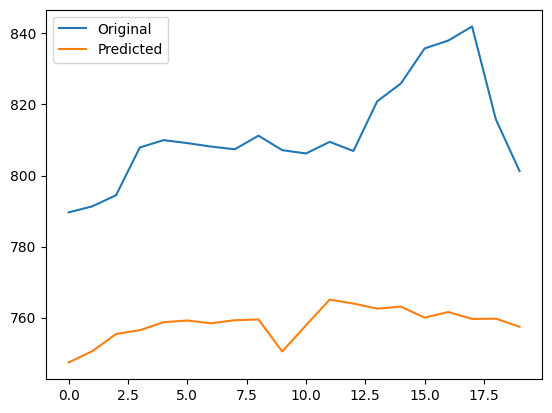

In [ ]:
plt.plot(test,label='Original')
plt.plot(pred1,label='Predicted')
plt.legend()

**LSTM**

In [ ]:
#### Input layer and First Hidden layer
lstm= tf.keras.models.Sequential()
lstm.add(tf.keras.layers.LSTM(units=60,return_sequences=True,input_shape=(60,1)))
#### Second Hidden layer
lstm.add(tf.keras.layers.LSTM(units=60,return_sequences=True))
#### Third Hidden layer
lstm.add(tf.keras.layers.LSTM(units=60,return_sequences=True))
#### Forth Hidden layer
lstm.add(tf.keras.layers.LSTM(units=60))
#### Output layer
lstm.add(tf.keras.layers.Dense(units=1))

In [ ]:
#### Model Compile
lstm.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
            loss=tf.keras.losses.mse)

In [ ]:
#### Model Training
lstm.fit(x_train,y_train,epochs=20,batch_size=40)

Epoch 1/20
30/30 ━━━━━━━━━━━━━━━━━━━━ 11s 115ms/step - loss: 0.0488
Epoch 2/20
30/30 ━━━━━━━━━━━━━━━━━━━━ 4s 119ms/step - loss: 0.0032
Epoch 3/20
30/30 ━━━━━━━━━━━━━━━━━━━━ 4s 136ms/step - loss: 0.0023
Epoch 4/20
30/30 ━━━━━━━━━━━━━━━━━━━━ 4s 144ms/step - loss: 0.0022
Epoch 5/20
30/30 ━━━━━━━━━━━━━━━━━━━━ 4s 134ms/step - loss: 0.0021
Epoch 6/20
30/30 ━━━━━━━━━━━━━━━━━━━━ 4s 133ms/step - loss: 0.0020
Epoch 7/20
30/30 ━━━━━━━━━━━━━━━━━━━━ 5s 163ms/step - loss: 0.0019
Epoch 8/20
30/30 ━━━━━━━━━━━━━━━━━━━━ 4s 124ms/step - loss: 0.0020
Epoch 9/20
30/30 ━━━━━━━━━━━━━━━━━━━━ 4s 118ms/step - loss: 0.0018
Epoch 10/20
30/30 ━━━━━━━━━━━━━━━━━━━━ 6s 149ms/step - loss: 0.0017
Epoch 11/20
30/30 ━━━━━━━━━━━━━━━━━━━━ 5s 138ms/step - loss: 0.0016
Epoch 12/20
30/30 ━━━━━━━━━━━━━━━━━━━━ 7s 199ms/step - loss: 0.0015
Epoch 13/20
30/30 ━━━━━━━━━━━━━━━━━━━━ 4s 131ms/step - loss: 0.0016
Epoch 14/20
30/30 ━━━━━━━━━━━━━━━━━━━━ 4s 132ms/step - loss: 0.0015
Epoch 15/20
30/30 ━━━━━━━━━━━━━━━━━━━━ 5s 169ms/step - l

In [ ]:
pred= lstm.predict(x_test)
pred1= min_max.inverse_transform(pred)
pred1

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step


array([[799.56573],
       [797.1163 ],
       [794.45245],
       [791.90106],
       [789.936  ],
       [788.8927 ],
       [788.8921 ],
       [789.86255],
       [791.59686],
       [793.89435],
       [796.45264],
       [798.98016],
       [801.30255],
       [803.26117],
       [805.00354],
       [806.74243],
       [808.7789 ],
       [811.2947 ],
       [814.3667 ],
       [817.4539 ]], dtype=float32)

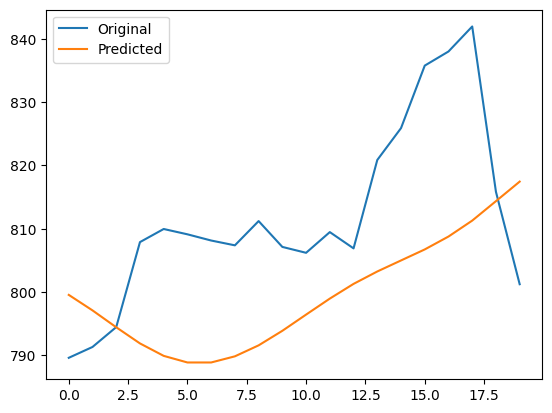

In [ ]:
plt.plot(test,label='Original')
plt.plot(pred1,label='Predicted')
plt.legend()

**GRU**

In [ ]:
#### Input layer and First Hidden layer
gru= tf.keras.models.Sequential()
gru.add(tf.keras.layers.GRU(units=60,return_sequences=True,input_shape=(60,1)))
#### Second Hidden layer
gru.add(tf.keras.layers.GRU(units=60,return_sequences=True))
#### Third Hidden layer
gru.add(tf.keras.layers.GRU(units=60,return_sequences=True))
#### Forth Hidden layer
gru.add(tf.keras.layers.GRU(units=60))
#### Output layer
gru.add(tf.keras.layers.Dense(units=1))

In [ ]:
#### Model Compile
gru.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
            loss=tf.keras.losses.mse)

In [ ]:
#### Model Training
gru.fit(x_train,y_train,epochs=20,batch_size=40)

Epoch 1/20
30/30 ━━━━━━━━━━━━━━━━━━━━ 17s 277ms/step - loss: 0.0346
Epoch 2/20
30/30 ━━━━━━━━━━━━━━━━━━━━ 4s 148ms/step - loss: 0.0017
Epoch 3/20
30/30 ━━━━━━━━━━━━━━━━━━━━ 5s 179ms/step - loss: 8.7927e-04
Epoch 4/20
30/30 ━━━━━━━━━━━━━━━━━━━━ 5s 163ms/step - loss: 7.3548e-04
Epoch 5/20
30/30 ━━━━━━━━━━━━━━━━━━━━ 4s 143ms/step - loss: 7.2310e-04
Epoch 6/20
30/30 ━━━━━━━━━━━━━━━━━━━━ 6s 199ms/step - loss: 6.5858e-04
Epoch 7/20
30/30 ━━━━━━━━━━━━━━━━━━━━ 4s 143ms/step - loss: 6.1302e-04
Epoch 8/20
30/30 ━━━━━━━━━━━━━━━━━━━━ 4s 146ms/step - loss: 5.7455e-04
Epoch 9/20
30/30 ━━━━━━━━━━━━━━━━━━━━ 6s 164ms/step - loss: 5.4119e-04
Epoch 10/20
30/30 ━━━━━━━━━━━━━━━━━━━━ 4s 143ms/step - loss: 5.1634e-04
Epoch 11/20
30/30 ━━━━━━━━━━━━━━━━━━━━ 6s 187ms/step - loss: 5.2588e-04
Epoch 12/20
30/30 ━━━━━━━━━━━━━━━━━━━━ 9s 141ms/step - loss: 4.7371e-04
Epoch 13/20
30/30 ━━━━━━━━━━━━━━━━━━━━ 7s 183ms/step - loss: 4.4477e-04
Epoch 14/20
30/30 ━━━━━━━━━━━━━━━━━━━━ 11s 212ms/step - loss: 4.2980e-04
Epoch 1

In [ ]:
pred= gru.predict(x_test)
pred1= min_max.inverse_transform(pred)
pred1

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 747ms/step


array([[784.31116],
       [786.6946 ],
       [789.7728 ],
       [792.79047],
       [801.9509 ],
       [807.72565],
       [808.72534],
       [807.8541 ],
       [806.84985],
       [808.75433],
       [807.4667 ],
       [805.8616 ],
       [807.2517 ],
       [806.6998 ],
       [814.5198 ],
       [821.8847 ],
       [830.3645 ],
       [835.03546],
       [838.5255 ],
       [823.622  ]], dtype=float32)

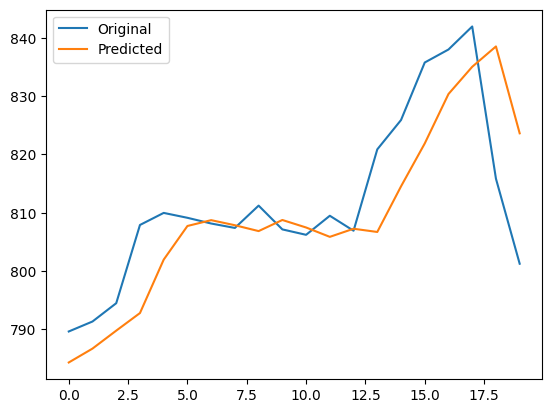

In [ ]:
plt.plot(test,label='Original')
plt.plot(pred1,label='Predicted')
plt.legend()